# 新的 Hypothesis：数学原理与可视化

[H1 动态清图](#h1) · [H2 运动补偿](#h2) · [H3 退化感知清图](#h3)

**展示方式：直接看公式和已保存的图；代码默认折叠，按需展开。** 重跑只需 Python、NumPy、Matplotlib，不依赖 ROS、仓库路径或额外数据文件。

三张图均为**人工构造的原理示意**；每块最后的小表才是本轮真实实验结果。

共同检验：**A 建图 → 冻结地图 → 另一次采集 B → 相同 AMCL 定位。**

**指标按任务选择：H1 的 A 看 DA/SA；H2 的 A 看地图几何误差；H3 的 A 看保护是否实际改变地图。定位误差只在冻结地图后的 B 评价。** DA/SA 是删除与保留比例，不代表几何精度。本轮 B 是运动过程中的定位测试，尚未测完整导航到达效果。

$$E_L(j)=\sqrt{\frac{1}{N}\sum_t\|\hat p_{j,t}^{B}-p_t^{B,*}\|^2},\qquad
\Delta E_L=E_L(\mathrm{baseline})-E_L(\mathrm{method}).$$

只有 $\Delta E_L>0$ 才表示定位改善；地图误差下降不自动意味着定位更好。真值只用于评分。

In [1]:
# 公共绘图设置；本格先运行一次
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import font_manager

available = {f.name for f in font_manager.fontManager.ttflist}
font = next((name for name in ['Microsoft YaHei', 'SimHei', 'Noto Sans CJK SC'] if name in available), 'DejaVu Sans')
plt.rcParams.update({'font.family': font, 'axes.unicode_minus': False,
                     'font.size': 11, 'axes.titlesize': 13, 'figure.dpi': 125,
                     'axes.spines.top': False, 'axes.spines.right': False})
BLUE, ORANGE, PURPLE, GREY = '#2376b7', '#d4782d', '#9756a6', '#7e8b99'

def tidy(ax):
    ax.grid(alpha=.16)
    ax.set_axisbelow(True)

<a id="h1"></a>
## H1｜用重复命中与自由射线清理动态残影

**假设：减少动态残影、保住静态结构，可以降低独立定位误差。**

对于栅格 $c$，$H_c$ 是重复命中的时间箱数，$F_c$ 是被自由射线穿过的时间箱数。

$$H_c=\sum_b\mathbf{1}[\text{时间箱 }b\text{ 内命中 }c],\qquad
F_c=\sum_b\mathbf{1}[\text{时间箱 }b\text{ 内自由射线穿过 }c].$$

$$K_c=\mathbf{1}[H_c\geq3\ \land\ H_c\geq1.5F_c].$$

$K_c=1$ 表示保留。一个时间箱为 **0.5 秒**，同一格在同一箱内只计一次；自由射线停在回波前 **15 cm**，不会穿过遮挡物后继续清图。

只检验 **A：DA 提高、SA 相对基线损失不超过 1 个百分点；B：位置 RMSE 降低**。DA 是已观测动态支持被删除的比例，SA 是已观测静态支持被保留的比例；静态对照没有动态目标，只报告 SA。

下面直接画出这个判据：**墙面重复命中；残影后来被自由射线穿过；观测少的静态结构也可能被误删。**

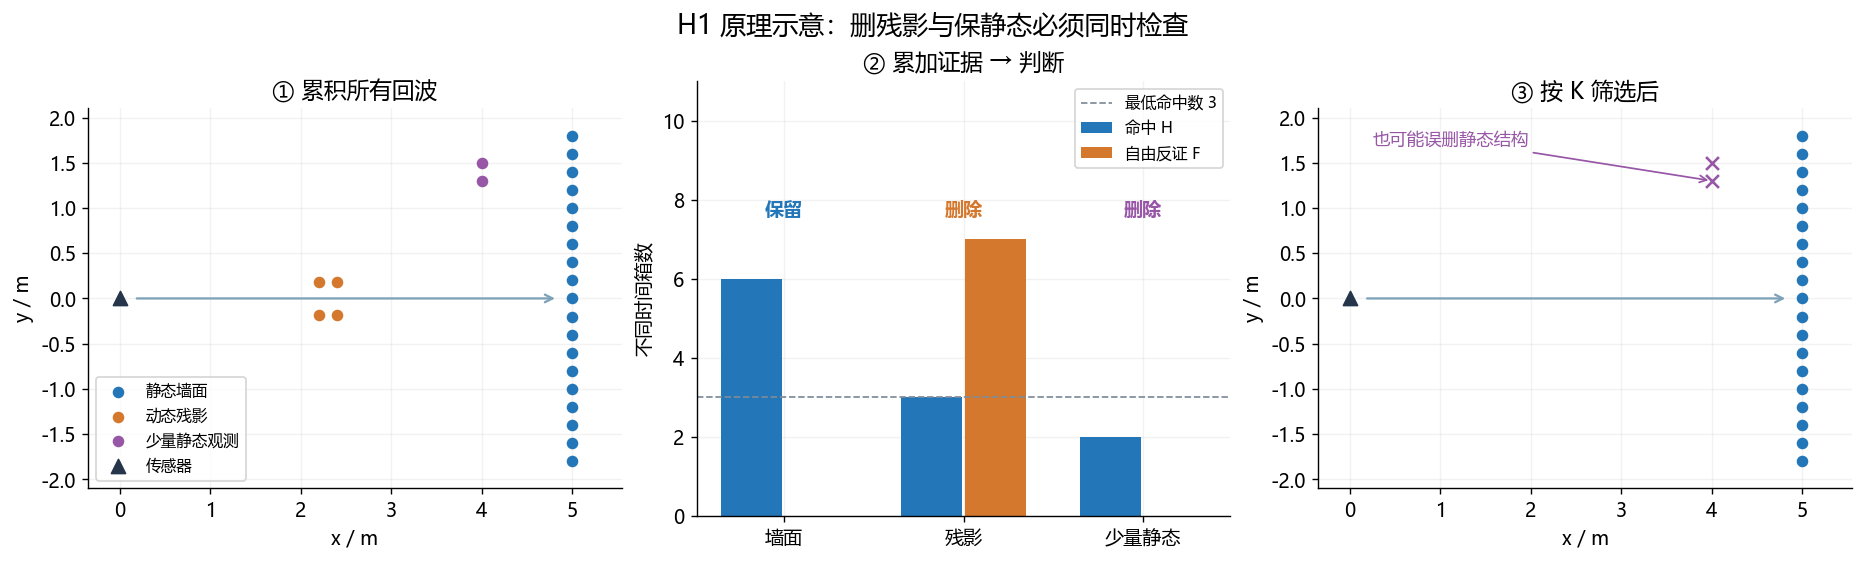

In [2]:
# 可改参数：保留阈值，与当前实现相同
min_hits, free_ratio = 3, 1.5
H = np.array([6, 3, 2])            # 墙面、动态残影、少量静态观测
F = np.array([0, 7, 0])
keep = (H >= min_hits) & (H >= free_ratio * F)  # 就是公式 K

wall = np.column_stack([np.full(19, 5.), np.linspace(-1.8, 1.8, 19)])
ghost = np.array([[2.2, -.18], [2.2, .18], [2.4, -.18], [2.4, .18]])
rare = np.array([[4., 1.3], [4., 1.5]])
groups = [wall, ghost, rare]
names = ['静态墙面', '动态残影', '少量静态观测']
colors = [BLUE, ORANGE, PURPLE]

fig, axes = plt.subplots(1, 3, figsize=(14.8, 4.4), layout='constrained')
for i, title in [(0, '① 累积所有回波'), (2, '③ 按 K 筛选后')]:
    ax = axes[i]
    for points, name, color, retained in zip(groups, names, colors, keep):
        if i == 0 or retained:
            ax.scatter(*points.T, color=color, s=32, label=name, zorder=3)
    ax.scatter(0, 0, color='#26364a', marker='^', s=65, label='传感器')
    ax.annotate('', xy=(4.85, 0), xytext=(.15, 0), arrowprops={'arrowstyle': '->', 'color': '#7da2b8', 'lw': 1.3})
    ax.set(title=title, xlim=(-.35, 5.55), ylim=(-2.1, 2.1), xlabel='x / m', ylabel='y / m')
    ax.set_aspect('equal'); tidy(ax)
axes[0].legend(loc='lower left', fontsize=9)
axes[2].scatter(*rare.T, color=PURPLE, marker='x', s=55)
axes[2].annotate('也可能误删静态结构', xy=rare[0], xytext=(.25, 1.7),
                 color=PURPLE, fontsize=10, arrowprops={'arrowstyle': '->', 'color': PURPLE})

ax = axes[1]
x = np.arange(3)
ax.bar(x-.18, H, width=.34, color=BLUE, label='命中 H')
ax.bar(x+.18, F, width=.34, color=ORANGE, label='自由反证 F')
ax.axhline(min_hits, color=GREY, ls='--', lw=1, label='最低命中数 3')
for i in x:
    ax.text(i, 7.6, '保留' if keep[i] else '删除', ha='center', color=colors[i], weight='bold')
ax.set(xticks=x, xticklabels=['墙面', '残影', '少量静态'], ylim=(0, 11), ylabel='不同时间箱数', title='② 累加证据 → 判断')
ax.legend(loc='upper right', fontsize=9); tidy(ax)
fig.suptitle('H1 原理示意：删残影与保静态必须同时检查', fontsize=15)
plt.show(); plt.close(fig)

**实际实验：动态场景，单轮 A/B。**

**A · 清图比例**

| 方法 | 残影删除 DA ↑ | 静态保留 SA ↑ |
| --- | --- | --- |
| 自写累积图 | 5.13% | 99.50% |
| 自写时序清图 | 94.87% | 92.55% |

**B · 冻结地图后定位**

| 地图／相同 AMCL | 位置 RMSE / cm ↓ |
| --- | --- |
| 自写累积图 | 5.718 |
| 自写时序清图 | 6.107 |

本轮残影减少，但静态损失超过 1 个百分点的容差，B 定位未改善，尚不支持 H1。

<a id="h2"></a>
## H2｜把不同时刻的点补偿到同一时刻

**假设：用轮式里程计补偿点的采样时间差，可以减小地图和独立定位误差。**

点 $p_i$ 在 $t_i$ 时刻采集；$\hat T(t)$ 是轮式里程计估计的传感器位姿；$t_e$ 是扫描末时刻。

$$\tilde p_i=\hat T(t_e)^{-1}\hat T(t_i)p_i.$$

先由 $\hat T(t_i)$ 把点变到公共坐标系，再由 $\hat T(t_e)^{-1}$ 变到扫描末时刻坐标系。实际实现对里程计位置线性插值，对展开后的偏航角插值。

图中用 **0、0.1、0.2 秒**三组点与理想里程计演示同一面墙；实际实验也是按真实采样时刻组合三个扇区。理想补偿后的直墙只解释机制，不是实测性能保证。

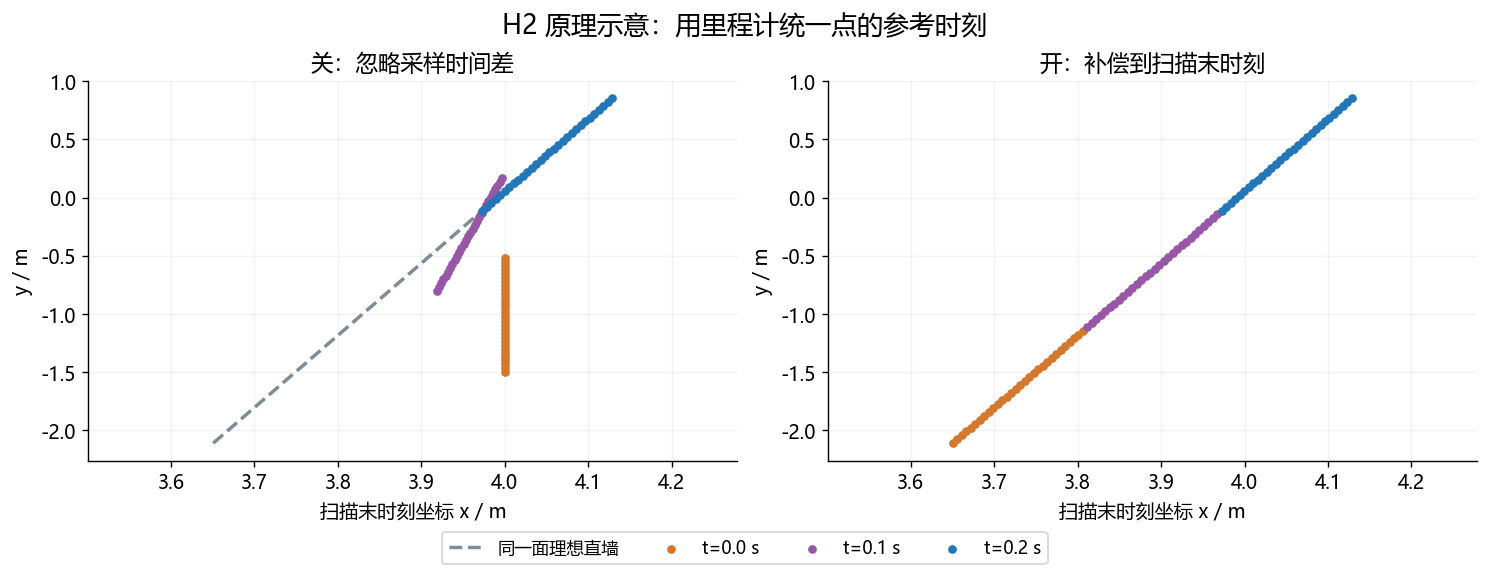

In [3]:
# 可改参数：扫描跨度、角速度、线速度
scan_span, yaw_speed, linear_speed = .2, .8, .3

def T_odom(t):
    angle = yaw_speed * t
    c, s = np.cos(angle), np.sin(angle)
    return np.array([[c, -s, linear_speed*t], [s, c, 0.], [0., 0., 1.]])

def apply_T(T, points):
    return points @ T[:2, :2].T + T[:2, 2]

wall_world = np.column_stack([np.full(90, 4.), np.linspace(-1.5, 1.5, 90)])
times = np.repeat([0., scan_span/2, scan_span], 30)
T_end = T_odom(scan_span)
raw, corrected = np.zeros_like(wall_world), np.zeros_like(wall_world)
for t in np.unique(times):
    mask = times == t
    T_i = T_odom(t)
    raw[mask] = apply_T(np.linalg.inv(T_i), wall_world[mask])
    corrected[mask] = apply_T(np.linalg.inv(T_end) @ T_i, raw[mask])  # 核心公式
reference = apply_T(np.linalg.inv(T_end), wall_world)
np.testing.assert_allclose(corrected, reference, atol=1e-12)

fig, axes = plt.subplots(1, 2, figsize=(11.8, 4.5), layout='constrained')
palette = [ORANGE, PURPLE, BLUE]
for ax, points, title in zip(axes, [raw, corrected], ['关：忽略采样时间差', '开：补偿到扫描末时刻']):
    ax.plot(*reference.T, '--', color=GREY, lw=2, label='同一面理想直墙')
    for t, color in zip(np.unique(times), palette):
        mask = times == t
        ax.scatter(*points[mask].T, s=16, color=color, label=f't={t:.1f} s', zorder=3)
    all_points = np.vstack([raw, corrected, reference])
    lo, hi = all_points.min(axis=0)-.15, all_points.max(axis=0)+.15
    ax.set(xlim=(lo[0], hi[0]), ylim=(lo[1], hi[1]), xlabel='扫描末时刻坐标 x / m', ylabel='y / m', title=title)
    tidy(ax)
handles, labels = axes[1].get_legend_handles_labels()
fig.legend(handles, labels, loc='outside lower center', ncol=4, fontsize=10)
fig.suptitle('H2 原理示意：用里程计统一点的参考时刻', fontsize=15)
plt.show(); plt.close(fig)

**实际实验：运动场景，单轮 A/B。**

**A · 地图几何：Eₘ 是地图点到已观测静态支持的距离 RMSE。**

| 方法 | 地图 Eₘ / cm ↓ |
| --- | --- |
| 自写补偿关 | 34.10 |
| 自写补偿开 | 4.57 |

**B · 冻结地图后定位**

| 地图／相同 AMCL | 位置 RMSE / cm ↓ |
| --- | --- |
| 自写补偿关 | 4.702 |
| 自写补偿开 | 4.707 |

本轮只支持建图改善；定位误差未下降。里程计误差、地图结构与匹配条件仍会影响下游定位。

<a id="h3"></a>
## H3｜检测退化，保护弱方向上的已有静态约束

**假设：清图时保留能约束弱方向的可靠静态结构，可以减少沿廊定位误差。**

局部平面法线为 $n_c$。机器人平移 $\delta p$ 时，该结构的点到面残差近似为 $n_c^T\delta p$，因此：

$$\sum_c(n_c^T\delta p)^2=\delta p^T G\delta p,\qquad G=\sum_{c\in C}n_cn_c^T.$$

$C$ 是至少命中两次、无自由射线反证、可估计法线的候选结构集合。平行墙的法线方向相近，沿走廊移动时残差变化小。

$$v_{\min}=\operatorname{eigvec}_{\min}(G),\qquad
D=\mathbf{1}[\lambda_{\min}(G)<0.25\lambda_{\max}(G)].$$

当 $D=1$ 时，对能约束弱方向的可靠结构降低删除阈值：

$$R_c=\mathbf{1}[H_c\geq2,\ F_c=0,\ |n_c^Tv_{\min}|>0.7],$$
$$K_c^{\mathrm{strict}}=\mathbf{1}[H_c\geq5\ \land\ H_c\geq1.5F_c],\qquad
K_c^{\mathrm{protected}}=K_c^{\mathrm{strict}}\ \lor\ (D\land R_c).$$

图中的短边缘**本来就存在于同一批观测中**，只是命中次数少，可能被统一阈值删除；没有向环境加入标志物。为简化图示，直线段法线由该段 PCA 得到；实际代码使用 0.30 m 局部邻域。

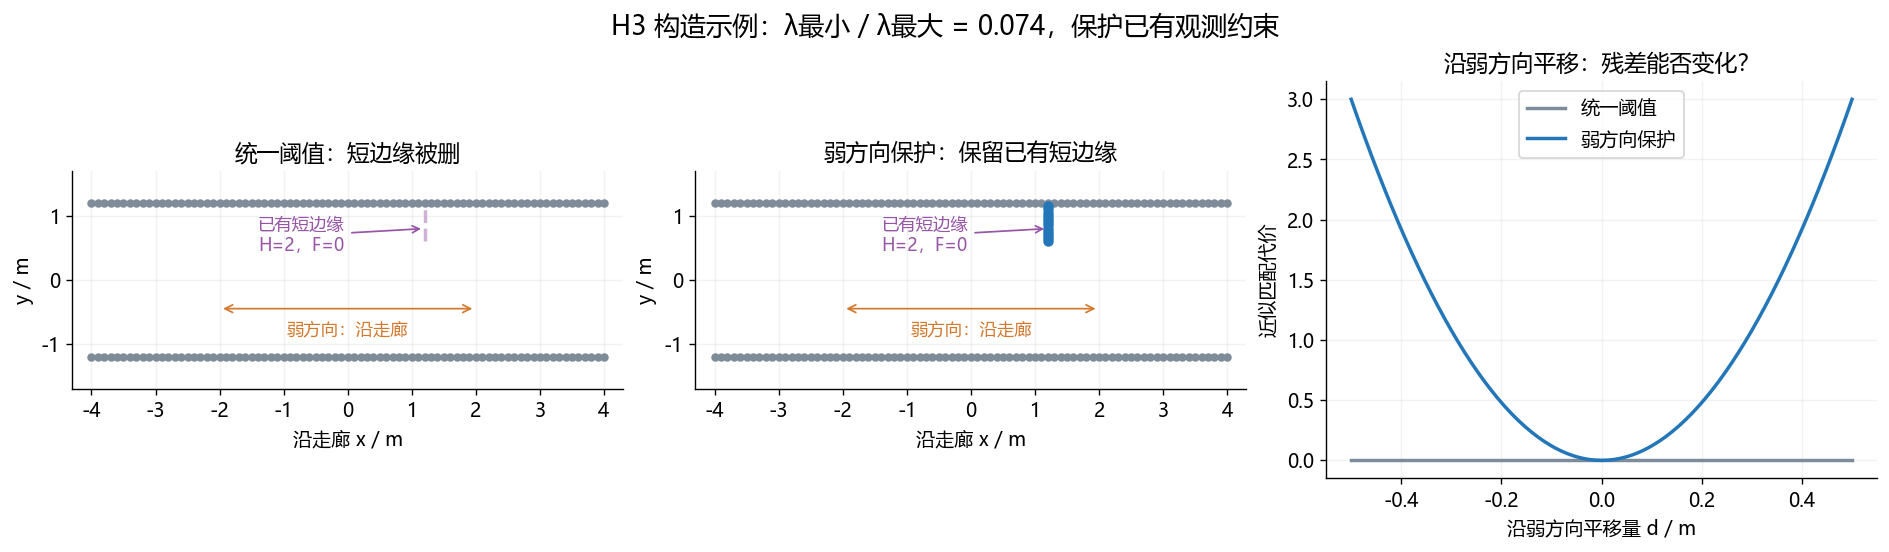

In [4]:
# 可改参数：统一阈值、保护阈值、退化判据
strict_hits, protected_hits, degeneracy_ratio = 5, 2, .25
upper = np.column_stack([np.linspace(-4., 4., 81), np.full(81, 1.2)])
lower = np.column_stack([np.linspace(-4., 4., 81), np.full(81, -1.2)])
edge = np.column_stack([np.full(12, 1.2), np.linspace(.6, 1.15, 12)])
segments = [upper, lower, edge]
points = np.vstack(segments)

def normal_from_pca(segment):
    centered = segment - segment.mean(axis=0)
    _, vectors = np.linalg.eigh(centered.T @ centered)
    return vectors[:, 0]  # 最小特征值方向是直线的法线

normals = np.vstack([np.tile(normal_from_pca(part), (len(part), 1)) for part in segments])
H = np.r_[np.full(162, 6), np.full(12, 2)]
F = np.zeros(len(points), dtype=int)
candidates = (H >= protected_hits) & (F == 0)
G = normals[candidates].T @ normals[candidates]
eigen, vectors = np.linalg.eigh(G)
weak = vectors[:, 0]
ratio = eigen[0] / eigen[1]
D = ratio < degeneracy_ratio
R = candidates & (np.abs(normals @ weak) > .7)
strict = (H >= strict_hits) & (H >= 1.5 * F)
protected = strict | (D & R)  # 与公式逐项一致
assert protected.sum() > strict.sum()  # 构造示例中确有少量可保护结构

fig, axes = plt.subplots(1, 3, figsize=(15., 4.3), layout='constrained')
for ax, keep, title in zip(axes[:2], [strict, protected], ['统一阈值：短边缘被删', '弱方向保护：保留已有短边缘']):
    ax.scatter(*points[keep & strict].T, color=GREY, s=15)
    ax.plot(*edge.T, '--', color=PURPLE, alpha=.45, lw=2)
    rescued = keep & ~strict
    ax.scatter(*points[rescued].T, color=BLUE, s=25, zorder=4)
    ax.annotate('已有短边缘\nH=2，F=0', xy=edge[4], xytext=(-1.4, .45), fontsize=10,
                color=PURPLE, arrowprops={'arrowstyle': '->', 'color': PURPLE})
    ax.annotate('', xy=(2., -.45), xytext=(-2., -.45), arrowprops={'arrowstyle': '<->', 'color': ORANGE})
    ax.text(0., -.85, '弱方向：沿走廊', color=ORANGE, ha='center', fontsize=10)
    ax.set(xlim=(-4.3, 4.3), ylim=(-1.7, 1.7), title=title, xlabel='沿走廊 x / m', ylabel='y / m')
    ax.set_aspect('equal'); tidy(ax)

d = np.linspace(-.5, .5, 151)
for keep, color, label in [(strict, GREY, '统一阈值'), (protected, BLUE, '弱方向保护')]:
    G_map = normals[keep].T @ normals[keep]
    cost = d**2 * (weak @ G_map @ weak)
    axes[2].plot(d, cost, color=color, label=label, lw=2)
axes[2].set(title='沿弱方向平移：残差能否变化？', xlabel='沿弱方向平移量 d / m', ylabel='近似匹配代价')
axes[2].legend(); tidy(axes[2])
fig.suptitle(f'H3 构造示例：λ最小 / λ最大 = {ratio:.3f}，保护已有观测约束', fontsize=15)
plt.show(); plt.close(fig)

实际检验的是沿走廊的位置误差，$u$ 为走廊单位方向：

$$E_{\parallel}=\sqrt{\frac{1}{N}\sum_t[u^T(\hat p_t-p_t^*)]^2}.$$

**实际实验：同一条长廊，单轮 A/B；沿廊指标取前 50 秒受限扫描阶段。**

**A · 保护规则额外保留 0 格，两张冻结地图字节相同。**

**B · 冻结地图后定位**

| 地图／相同 AMCL | 沿廊 E∥ / cm ↓ |
| --- | --- |
| 统一阈值 | 80.555 |
| 退化感知保护 | 80.555 |

**本轮额外保留 0 格，两张冻结地图字节相同，没有定位改善，尚不支持 H3。** 上图仅说明规则在存在可保护结构时怎样起作用。完全缺少沿廊信息时，保护规则无法凭空创造约束。

真实数值来自 `own-hypotheses-20261016` 封存记录；仅一轮探索实验。定位均使用共同时间点上的相同 AMCL 评价，示意图没有运行定位器。

[当前自写实现](https://github.com/p20030920p/SLAM_Learning/blob/86f84e8/src/slam_learning/runtime/own_mapping.py) · [实际 A/B 录像与指标](https://github.com/p20030920p/SLAM_Learning/blob/86f84e8/docs/HOME.zh-CN.md#hypothesis-test-index)